# 02 Preprocessing QA: what will the model actually see?

In [1]:
# load the saved patches and index so every check below uses exactly what the model will be given
from pathlib import Path

import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed" / "nodules.csv").is_file() and (p / "data" / "VOIs" / "VOIs").is_dir())
PROC = ROOT / "data" / "processed"
VOI_IMG = ROOT / "data" / "VOIs" / "VOIs" / "image"
FIGS = ROOT / "results" / "figures" / "preprocessing"
FIGS.mkdir(parents=True, exist_ok=True)
NAME = "v1"

X = np.load(PROC / f"patches_{NAME}_X.npy")
M = np.load(PROC / f"patches_{NAME}_mask.npy")
idx = pd.read_csv(PROC / f"patches_{NAME}_index.csv")
nod = pd.read_csv(PROC / "nodules.csv")
idx = idx.merge(nod[["voi_name", "diameter_mm", "thickness", "sz", "sx"]], on="voi_name", how="left")
assert len(idx) == len(X) == len(M)
C = X.shape[1] // 2
print(X.shape, X.dtype, "range", float(X.min()), float(X.max()), "| masks", M.shape)

(994, 1, 64, 64) float32 range 0.0 1.0 | masks (994, 64, 64)


In [2]:
# make sure nothing is broken numerically and that every mask landed inside the window
assert np.isfinite(X).all()
print("empty mask patches:", int((M.sum(axis=(1, 2)) == 0).sum()))
print("mask pixels in patch:", pd.Series(M.sum(axis=(1, 2))).describe().round(1).to_dict())
yy, xx = np.indices(M.shape[1:])
cy = (M * yy).sum(axis=(1, 2)) / M.sum(axis=(1, 2)).clip(min=1)
cx = (M * xx).sum(axis=(1, 2)) / M.sum(axis=(1, 2)).clip(min=1)
print("mask centroid offset from patch centre (px): mean",
      round(float(np.hypot(cx - 31.5, cy - 31.5).mean()), 2), "max", round(float(np.hypot(cx - 31.5, cy - 31.5).max()), 2))

empty mask patches: 0
mask pixels in patch: {'count': 994.0, 'mean': 367.6, 'std': 465.9, 'min': 43.0, '25%': 104.2, '50%': 175.0, '75%': 403.5, 'max': 3185.0}
mask centroid offset from patch centre (px): mean 0.81 max 6.0


In [3]:
# check padding is not a shortcut: if pad fraction predicts the label or size, the preprocessing leaks
print(idx["pad_fraction"].describe().round(3))
print("share of patches with any padding:", round(float((idx["pad_fraction"] > 0).mean()), 3))
print("pad_fraction AUC vs malignant:", round(roc_auc_score(idx["malignant"], idx["pad_fraction"]), 3))
print(idx[["pad_fraction", "diameter_mm", "sx", "sz"]].corr(method="spearman").round(2)["pad_fraction"])
print(idx.groupby("thickness")["pad_fraction"].mean().round(3))

count    994.000
mean       0.160
std        0.147
min        0.000
25%        0.016
50%        0.136
75%        0.261
max        0.629
Name: pad_fraction, dtype: float64
share of patches with any padding: 0.756
pad_fraction AUC vs malignant: 0.418
pad_fraction    1.00
diameter_mm    -0.32
sx             -0.94
sz             -0.30
Name: pad_fraction, dtype: float64
thickness
1.25             0.148
thick (>=1.8)    0.126
thin (<=1.0)     0.208
Name: pad_fraction, dtype: float64


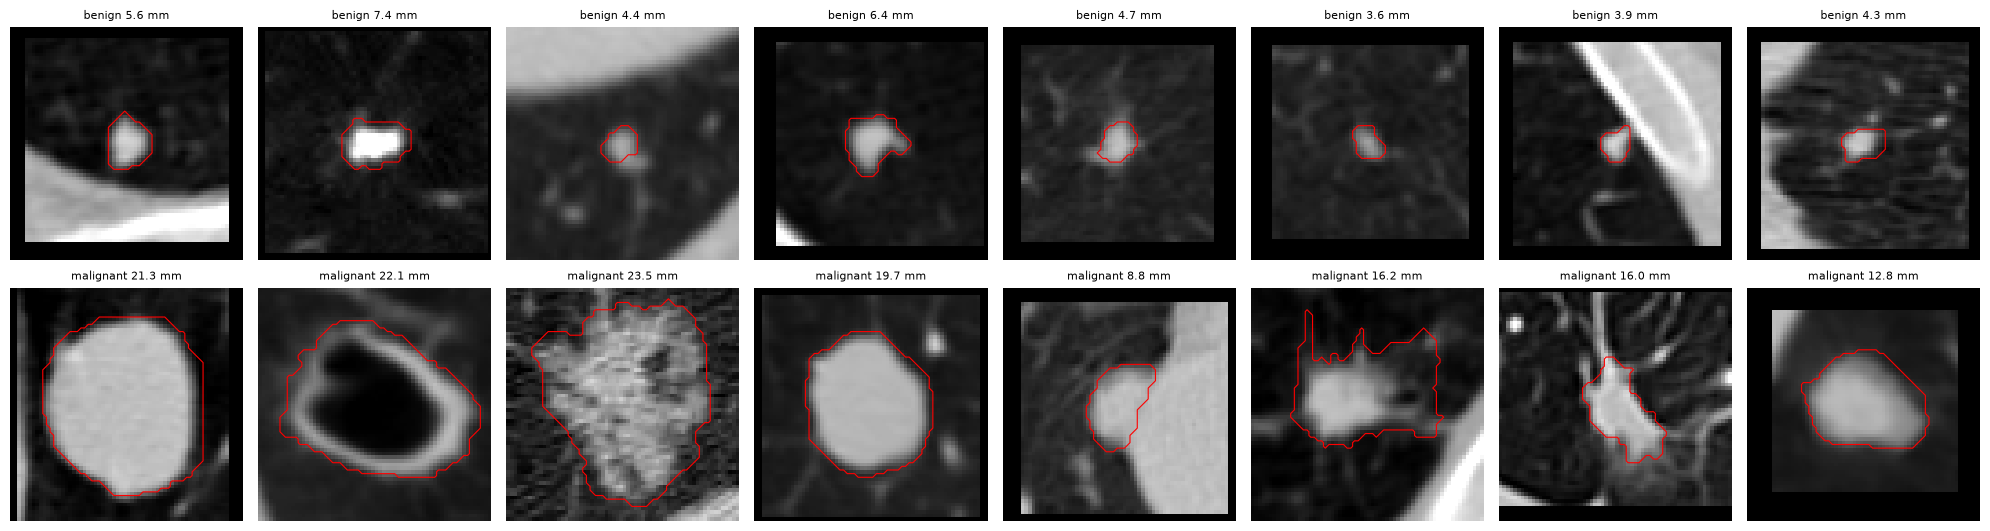

In [4]:
# eyeball centred patches with mask outlines to confirm the nodule sits in the middle for both classes
fig, axes = plt.subplots(2, 8, figsize=(20, 5.5))
for row, c in enumerate((0, 1)):
    for col, i in enumerate(idx[idx["malignant"] == c].sample(8, random_state=1).index):
        ax = axes[row, col]
        ax.imshow(X[i, C], cmap="gray", vmin=0, vmax=1, origin="lower")
        ax.contour(M[i].astype(float), levels=[0.5], colors="r", linewidths=0.8)
        ax.set_title(f"{'malignant' if c else 'benign'} {idx.loc[i, 'diameter_mm']:.1f} mm", fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.savefig(FIGS / f"patches_{NAME}_montage.png", dpi=150)
plt.show()

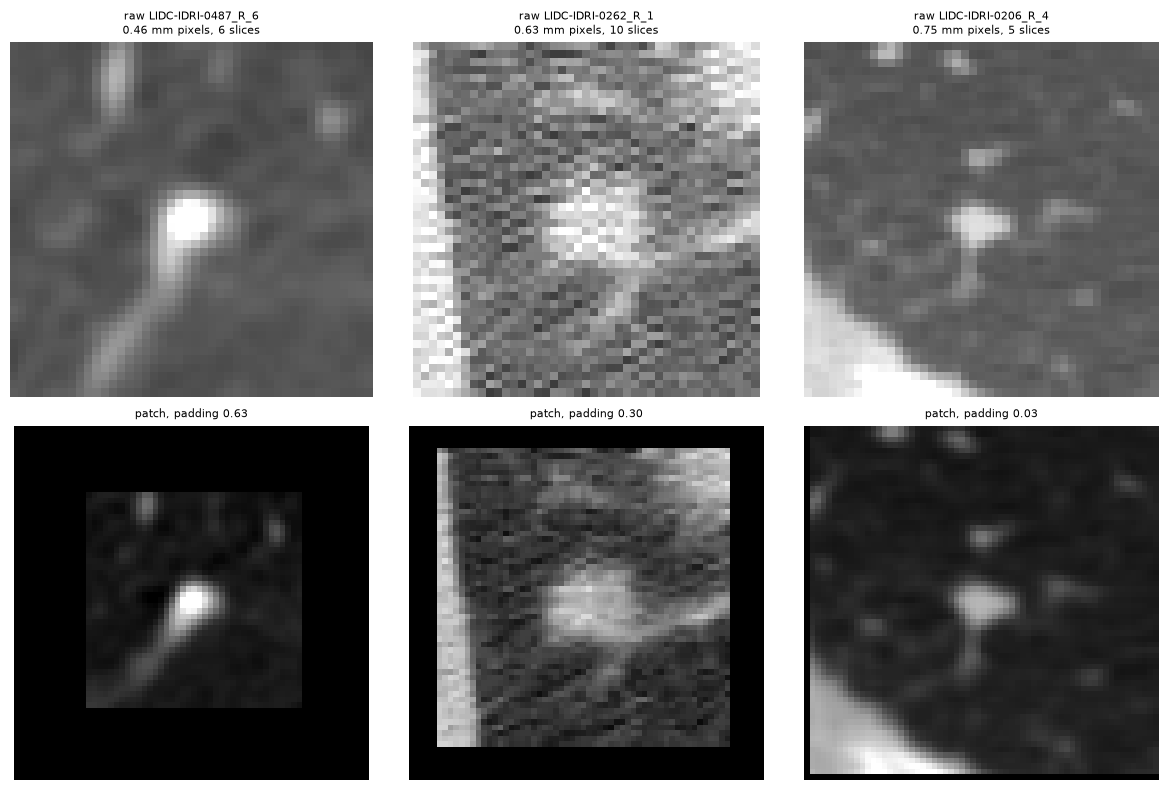

In [5]:
# compare the raw VOI slice with its patch for hard cases (most padding, RAS-stored, random)
inv = pd.read_csv(PROC / "image_inventory.csv")
ras = set(inv.loc[(inv["kind"] == "voi_image") & (inv["orientation"] == "RAS"), "file"])
picks = [idx["pad_fraction"].idxmax(), idx[idx["voi_name"].isin(ras)].index[0], idx.sample(1, random_state=3).index[0]]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for col, i in enumerate(picks):
    name = idx.loc[i, "voi_name"]
    img = nib.as_closest_canonical(nib.load(VOI_IMG / name))
    vol = np.asanyarray(img.dataobj).astype(np.float32)
    sx, sy = img.header.get_zooms()[:2]
    axes[0, col].imshow(vol[:, :, vol.shape[2] // 2].T, cmap="gray", vmin=-1400, vmax=200, origin="lower", aspect=sy / sx)
    axes[0, col].set_title(f"raw {name[:-7]}\n{sx:.2f} mm pixels, {vol.shape[2]} slices", fontsize=8)
    axes[1, col].imshow(X[i, C], cmap="gray", vmin=0, vmax=1, origin="lower")
    axes[1, col].set_title(f"patch, padding {idx.loc[i, 'pad_fraction']:.2f}", fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS / f"patches_{NAME}_raw_vs_patch.png", dpi=150)
plt.show()

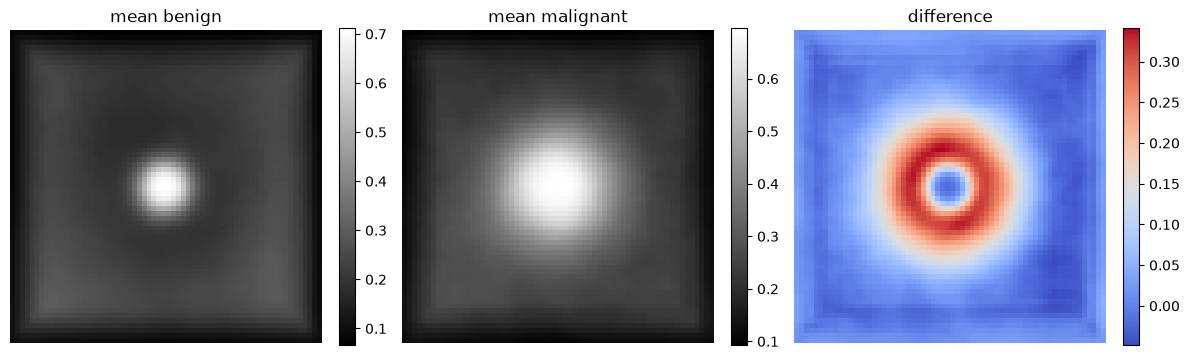

In [6]:
# average patch per class to see the systematic differences a model could learn
mean_b = X[(idx["malignant"] == 0).values, C].mean(axis=0)
mean_m = X[(idx["malignant"] == 1).values, C].mean(axis=0)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, img, title in zip(ax, [mean_b, mean_m, mean_m - mean_b], ["mean benign", "mean malignant", "difference"]):
    im = a.imshow(img, cmap="gray" if title != "difference" else "coolwarm", origin="lower")
    a.set_title(title)
    a.axis("off")
    plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout()
plt.savefig(FIGS / f"patches_{NAME}_class_means.png", dpi=150)
plt.show()